# 01 — Exploratory Data Analysis: Business Entity Resolution

Goal: understand the structure of the three sources, the ground truth, and the noise patterns
so we can design normalization, blocking, and the matching model.

Sections
1. Load & basic shapes
2. Missingness & country distribution
3. Ground-truth structure (cluster sizes, singletons, one-S1-per-record)
4. Scripts / transliteration
5. Name noise (legal suffixes, junk prefixes, domains)
6. Address format (components, numbers, PIN/ZIP, `null` tokens)
7. Pair-level similarity: positives vs random vs hard negatives
8. Test set & the unseen country (France)
9. Takeaways

In [1]:
import re, unicodedata
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_colwidth', 120)
pd.set_option('display.width', 200)
sns.set_theme(style='whitegrid')

DATA = Path('../dataset')

def read(path):
    return pd.read_csv(path, sep='\t', keep_default_na=False, dtype=str, quoting=3)

## 1. Load & basic shapes

In [2]:
tr = {i: read(DATA / f'train/train_source{i}.tsv') for i in (1, 2, 3)}
te = {i: read(DATA / f'test/test_source{i}.tsv') for i in (1, 2, 3)}
gt = read(DATA / 'train/train_ground_truth.tsv')

pd.DataFrame({
    f'{split}_S{i}': [len(d[i]), d[i].entity_id.nunique()]
    for split, d in [('train', tr), ('test', te)] for i in (1, 2, 3)
}, index=['rows', 'unique_ids']).T

,rows,unique_ids
train_S1,2206821,2206821
train_S2,5034616,5034616
train_S3,5285603,5285603
test_S1,1732544,1732544
test_S2,4887273,4887273
test_S3,5082316,5082316


In [3]:
for i in (1, 2, 3):
    print(f'--- train S{i}')
    display(tr[i].sample(5, random_state=1))

--- train S1


,entity_id,business_name,business_address,country
1524360,S1-214435868,Meek Principal,"Fort Recovery, OH, 2620 Sawmill Road",US
585589,S1-522572257,Family Charities II,"2819 Sanctuary Cove, Katy, TX",US
855245,S1-998727651,Global Complete Vendome LLC,"3106 London Lane, Missouri City, TX",US
1926943,S1-431969295,Taylor Battery Holdings,"3142 Village Pine Cove, West Valley City, UT",US
2038564,S1-825177873,Complete Premier Tbk,"25622 6, Nappanee, IN",US


--- train S2


,entity_id,business_name,business_address,country
293730,S2-153809211,Royal Safe Paceline Inc,"HOMELAND AVE, NULL, NORMAN, OK",US
4038314,S2-860628396,Heritage Éducation Products,"7582 EAST POINT DOUGLAS RD, COTTAGE GROVE, MN",US
1071002,S2-214575246,Knight Educational Society Private Limited,"Karnataka, 50 , KNO 499/499, BCMC HBCS, RAGHUVANAHALLI, BANGALORE SOUTH",India
691119,S2-300083710,HART VALLEY LÍBERTY CENTER,"FOURTEENTH STREET, SAN BERNARDINO TOOWNSHIP, CA",US
2554869,S2-281128880,Rainbow Partners Center,"Gujarat, 401-402, SHREEYA ATLANTA, NR SAHJANAND BUNGLOW, AHMADABAD CITY",India


--- train S3


,entity_id,business_name,business_address,country
3874110,S3-353598503,Prairie Futurecorp Inc,"5402 Alexander Hill Road, Washington, Indiana",US
1348849,S3-113330256,Associates + Co Care Ltd,"Plot No. 23, S.v .Co.Operative Industrial Estates, Balanagar, Hyderabad, TG",India
2825306,S3-518854530,Pediatric Dentistry Group Of Pittsburg,"2254, Pittsburg, Texas",US
4285132,S3-719640223,Flexible Consultancy Private (Limited),"44, Girwa, राजस्थान",India
4485828,S3-995424349,राम प्रोडक्ट्स प्राइवेट लिमिटेड,"Rajendra Nagar Rafi Nagar Mankapur, Gonda, UP",India


## 2. Missingness & country distribution

In [4]:
rows = []
for split, d in [('train', tr), ('test', te)]:
    for i in (1, 2, 3):
        df = d[i]
        rows.append({
            'split': split, 'source': f'S{i}',
            'empty_name': (df.business_name.str.strip() == '').mean(),
            'empty_addr': (df.business_address.str.strip() == '').mean(),
            'addr_has_null_token': df.business_address.str.contains(r'\bnull\b', case=False).mean(),
        })
pd.DataFrame(rows).style.format({c: '{:.2%}' for c in ['empty_name', 'empty_addr', 'addr_has_null_token']})

,split,source,empty_name,empty_addr,addr_has_null_token
0,train,S1,0.00%,0.00%,0.00%
1,train,S2,0.00%,3.36%,2.62%
2,train,S3,0.00%,3.33%,2.48%
3,test,S1,0.00%,0.00%,0.00%
4,test,S2,0.00%,2.65%,2.16%
5,test,S3,0.00%,2.68%,2.08%


,train_S1,train_S2,train_S3,test_S1,test_S2,test_S3
country,,,,,,
US,1323633,3016817,3170056,663106,1871330,1945701
India,883188,2017799,2115547,809986,2312565,2405000
France,0,0,0,259452,703378,731615


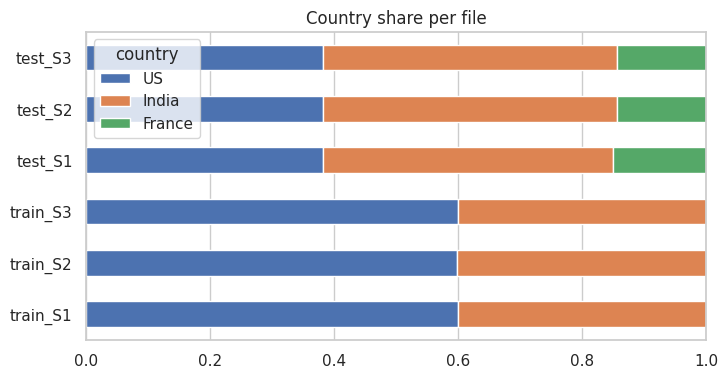

In [5]:
cc = pd.concat([
    d[i].country.value_counts().rename(f'{split}_S{i}')
    for split, d in [('train', tr), ('test', te)] for i in (1, 2, 3)
], axis=1).fillna(0).astype(int)
display(cc)
(cc / cc.sum()).T.plot.barh(stacked=True, figsize=(8, 4), title='Country share per file');

## 3. Ground-truth structure

S1 entities: 2206821 | in S1 file: 2206821 | all S1 covered: True
singleton rate: 0.0558


,entities,singleton_rate,mean_matches,mean_s2,mean_s3
country,,,,,
India,883188,0.055878,3.464543,1.676364,1.788179
US,1323633,0.055828,3.459057,1.671969,1.787088


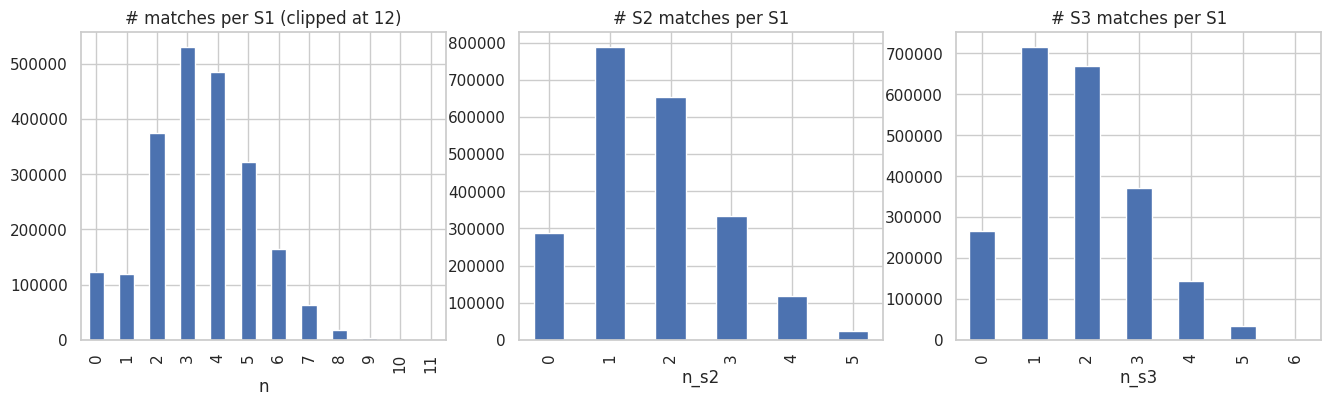

In [6]:
gt['ids'] = gt.matched_entity_ids.map(lambda s: s.split(',') if s else [])
gt['n'] = gt.ids.map(len)
gt['n_s2'] = gt.ids.map(lambda l: sum(x.startswith('S2') for x in l))
gt['n_s3'] = gt.ids.map(lambda l: sum(x.startswith('S3') for x in l))
gt = gt.merge(tr[1][['entity_id', 'country']], left_on='source1_entity_id', right_on='entity_id').drop(columns='entity_id')

print('S1 entities:', len(gt), '| in S1 file:', len(tr[1]), '| all S1 covered:', set(gt.source1_entity_id) == set(tr[1].entity_id))
print('singleton rate:', (gt.n == 0).mean().round(4))
display(gt.groupby('country').agg(entities=('n', 'size'), singleton_rate=('n', lambda x: (x == 0).mean()),
                                  mean_matches=('n', 'mean'), mean_s2=('n_s2', 'mean'), mean_s3=('n_s3', 'mean')))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
gt.n.clip(upper=12).value_counts().sort_index().plot.bar(ax=ax[0], title='# matches per S1 (clipped at 12)')
gt.n_s2.clip(upper=8).value_counts().sort_index().plot.bar(ax=ax[1], title='# S2 matches per S1')
gt.n_s3.clip(upper=8).value_counts().sort_index().plot.bar(ax=ax[2], title='# S3 matches per S1');

In [7]:
pairs = gt[['source1_entity_id', 'ids', 'country']].explode('ids').dropna(subset=['ids']).rename(columns={'ids': 'other_id'})
print('positive pairs:', len(pairs))

# Is every S2/S3 record linked to at most one S1?
per_rec = pairs.other_id.value_counts()
print('S2/S3 records linked to >1 S1:', int((per_rec > 1).sum()))

# Unmatched (decoy) S2/S3 records
matched = set(pairs.other_id)
for i in (2, 3):
    df = tr[i]
    m = df.entity_id.isin(matched)
    print(f'S{i}: unmatched fraction = {1 - m.mean():.2%}',
          df.assign(m=m).groupby('country').m.apply(lambda x: f'{1 - x.mean():.2%}').to_dict())

positive pairs: 7638365


S2/S3 records linked to >1 S1: 0


S2: unmatched fraction = 26.64% {'India': '26.63%', 'US': '26.64%'}


S3: unmatched fraction = 25.37% {'India': '25.35%', 'US': '25.38%'}


In [8]:
# Lookup table for all train records + a 300k sample of positive pairs
rec = pd.concat([tr[1], tr[2], tr[3]]).set_index('entity_id')
P = pairs.sample(300_000, random_state=0).reset_index(drop=True)
L = rec.loc[P.source1_entity_id].reset_index()
R = rec.loc[P.other_id].reset_index()
print('matched pair same country:', (L.country.values == R.country.values).mean())

g_ids = gt.set_index('source1_entity_id').ids

def show_cluster(s1_id):
    return rec.loc[[s1_id] + g_ids[s1_id]]

for c in ['US', 'India']:
    for s in gt[(gt.country == c) & (gt.n >= 4)].sample(2, random_state=3).source1_entity_id:
        display(show_cluster(s))

matched pair same country: 1.0


,business_name,business_address,country
entity_id,,,
S1-551764957,Mendoza United Enterprise LLC,"1515 16th Street, Unit 818, Mineral Wells, TX",US
S2-535434825,Mendoza United Enterprise,"1515 16TH STREET, MINERAL WELLS, TX",US
S2-807488665,Mendoza United LLC Enterprise,"TX, MINERAL WELLS, 1515 16TH ST",US
S2-733047955,Mendoza United Enterise LLC,"1515 16TH STREET, MINERAL WELLS, TX",US
S3-822885303,Mendoza United,"16th Street, Unit 818, Mineral Wells, Texas",US
S3-142272161,[LLC] Mendoza United Eniterprise,"1515 16th Street, Unit 818, Mineral Wells, Texas",US
S3-70854729,Mendoza LLC Enterprise United (ID: 84177),"1515 16th St, # 818, Mineral Wells, Texas",US
S3-92489018,Rizanylacalo Formerly Mendoza United Enterprise LLC,"1515 16th Street, Unit 818, Mineral Wells, TX",US


,business_name,business_address,country
entity_id,,,
S1-157082871,"Gonsalez, Ayn, DDS","3611 11th Avenue, Seattle, WA",US
S2-161219808,Gonsalez Ayn DDS,"3611 11TH AVE, SEATTLE, WA",US
S2-225438406,"GONSALEZ, AL DDS","3611 11TH AVENUE, SEATTLE, WA",US
S3-366039504,"Gonsalez, Ayn,","3611 Eleventh Avenue, Seattle, Washington",US
S3-363518840,"DDS AYN, GONSALEZ,","3611 11th Ave, Seattle, Washington",US


,business_name,business_address,country
entity_id,,,
S1-942589184,Shree Solutions Private Limited,"Esteem Heritage Apartment, Pearl G4, Rose Garden Road, J P Nagar, 5Th Phase, Bangalore South, Bangalore, Karnataka",India
S2-325621514,Shree Solutions Private Limited,"ESTEEM HERITAGE APARTMENT, PEARL G4, ROSE GARDEN ROAD, J P NAGAR, 5TH PHASE, BANGALORE SOUTH, Karnataka",India
S3-608274492,Smt Shree Solutions Private [Limited],"Plot 926. Esteem Heritage Apartment, Pearl G4, Rose Garden Road, J P Nagar, 5Th Phase, Bangalore South, Bangalore, ಕ...",India
S3-331062641,Dr Shree Solutions Private Ltd,"Bangalore South, Pearl G4, Rose Garden Road, J P Nagar, 5Th Phase, Bangalore, Plot 926. Esteem Heritage Apartment, KA",India
S3-515717089,Shree Solutions [Private],"Plot 926. Esteem Heritage Apartment, Pearl G4, Rose Garden Road, J P Nagar, 5Th Phase, Bangalore South, Bangalore, ಕ...",India
S3-323371217,shree solutions private limited,"Plot 926. Esteem Heritage Apartment, Pearl G4, Rose Garden Road, J P Nagar, 5Th Phase, Bangalore, Bangalore South, KA",India
S3-283437457,Drexveoio dba Shree Solutions Private Limited,"Esteem Heritage Apartment, Pearl G4, Rose Garden Road, J P Nagar, 5Th Phase, Bangalore South, Bangalore, Karnataka",India


,business_name,business_address,country
entity_id,,,
S1-145432572,Apex Foods LLP,"Pine Crest, B-0501, Godrej Garden City, Dascroi, Ahmedabad, Gujarat",India
S2-485472467,એપેક્સ ફૂડ્સ એલએલપી,"NO 622 PINE CREST, DASCROI, AHMEDABAD, Gujarat",India
S2-635007591,APEX FONNODS LLP,"H.NO 622 PINE CREST, B-0501, GODREJ GARDEN CITY, DASCROI, ગુજરાત",India
S2-965129489,Apex F0ods LLP,"Gujarat, H.NO 622 PINE CREST, B-0501, GODREJ GARDEN CITY, DASCROI",India
S2-712247895,apexfoods.com,"NO. 622 PINE CREST, B-0501, GODREJ GARDEN CITY, DASCROI, ગુજરાત",India
S3-809019966,Mr Apex Foods,,India


## 4. Scripts / transliteration

In [9]:
def script_of(s):
    for ch in s:
        if ch.isalpha() and ord(ch) > 0x24F:
            return unicodedata.name(ch, 'UNKNOWN').split(' ')[0]
    return 'LATIN'

cols = {}
for split, d in [('train', tr), ('test', te)]:
    for i in (1, 2, 3):
        s = d[i].sample(min(200_000, len(d[i])), random_state=0)
        for col in ['business_name', 'business_address']:
            cols[f'{split}_S{i}_{col.split("_")[1]}'] = s[col].map(script_of).value_counts(normalize=True)
pd.DataFrame(cols).fillna(0).style.format('{:.2%}')

,train_S1_name,train_S1_address,train_S2_name,train_S2_address,train_S3_name,train_S3_address,test_S1_name,test_S1_address,test_S2_name,test_S2_address,test_S3_name,test_S3_address
BENGALI,0.00%,0.00%,0.63%,0.64%,0.35%,0.57%,0.00%,0.00%,0.72%,0.73%,0.41%,0.69%
DEVANAGARI,0.00%,0.00%,5.32%,5.44%,3.00%,5.20%,0.00%,0.00%,6.37%,6.59%,3.59%,6.41%
GUJARATI,0.00%,0.00%,0.60%,0.63%,0.32%,0.60%,0.00%,0.00%,0.70%,0.73%,0.39%,0.74%
GURMUKHI,0.00%,0.00%,0.13%,0.14%,0.08%,0.13%,0.00%,0.00%,0.16%,0.17%,0.08%,0.16%
KANNADA,0.00%,0.00%,0.72%,0.74%,0.41%,0.72%,0.00%,0.00%,0.96%,0.92%,0.52%,0.88%
LATIN,100.00%,100.00%,90.68%,90.65%,94.72%,91.05%,100.00%,100.00%,88.76%,88.68%,93.65%,89.03%
MALAYALAM,0.00%,0.00%,0.37%,0.31%,0.20%,0.30%,0.00%,0.00%,0.46%,0.36%,0.26%,0.38%
ORIYA,0.00%,0.00%,0.15%,0.11%,0.08%,0.11%,0.00%,0.00%,0.18%,0.14%,0.09%,0.13%
TAMIL,0.00%,0.00%,0.64%,0.66%,0.39%,0.67%,0.00%,0.00%,0.78%,0.83%,0.45%,0.80%
TELUGU,0.00%,0.00%,0.76%,0.69%,0.44%,0.64%,0.00%,0.00%,0.92%,0.84%,0.56%,0.78%


In [10]:
# Non-Latin examples paired with their S1 (Latin) counterpart
nl = R.business_name.map(script_of) != 'LATIN'
pd.DataFrame({'s1_name': L.business_name[nl], 'other_name': R.business_name[nl],
              'other_addr': R.business_address[nl]}).sample(12, random_state=0)

,s1_name,other_name,other_addr
237167,Aditya Solutions Private Limited,आदित्य सॉल्यूशंस प्राइवेट लिमिटेड,"NO 113, UDYOG KENDRA-II ECOTECH-III, GREATER NOIDA, GAUTAM BUDDHA NAGAR, Uttar Pradesh"
179606,Bombay Trading,बॉम्बे ट्रेडिंग,"G-C-21 ZOOM PLAZA PREMISES CHS, NEXT TO GORAI BEST DEPOT BORIVALL, BOMBAY, MUMBAI CITY, महाराष्ट्र"
7088,North Food Private Limited,नॉर्थ फूड प्राइवेट लिमिटेड,"G-01205A SAVIOUR GREEN ARCH, BISHRAKH, GAUTAM BUDDHA NAGAR, Uttar Pradesh"
272986,Apex It Private Limited,एपेक्स आईटी प्राइवेट लिमिटेड,"PLOT NO 135-A GROUND FL, LEFT SIDE KH NO-1175, NEW DELHI, SOUTH WEST DELHI, Delhi"
290141,Anand Logistics Private Limited,आनंद लॉजिस्टिक्स प्राइवेट लिमिटेड,"PLOT-G- HIG-150, MHADASANT TUKARAM NAGAR, PUNE, PUNE CITY, महाराष्ट्र"
109934,Arihant Ventures Pvt Ltd,अरिहंत वेंचर्स प्रा. लि.,"Iind Floor, Rewa, Rewa Main, MP"
286726,Shivam International Private Limited,शिवम इंटरनेशनल प्राइवेट लिमिटेड,"JAIPUR, Rajasthan, 305-B"
161309,Urban Royal Technologies Pvt Ltd,আরবান রয়্যাল টেকনোলজিস প্রাইভেট লিমিটেড,"25, MUZAFFAR AHMED STREET, P.S. PARK STREET, GROUND FLOOR, KOLKATA, KOLKATA, HOWRAH, West Bengal"
185129,Sai Developers Private Limited,సాయి డెవలపర్స్ ప్రైవేట్ లిమిటెడ్,"VISAKHAPATNAM REGION, KAILASA METTA SIRIPURAM UPLANDS, Andhra Pradesh, 10-27-8/1, VISHAKHAPATNAM"
100173,International Systems Limited,इंटरनेशनल सिस्टम्स लिमिटेड,"13 E-25 SOUTH EXTENSION, NEW DELHI, DELHI"


## 5. Name noise

In [11]:
def toks(s):
    return re.findall(r'[a-z0-9]+', unicodedata.normalize('NFKD', s.lower()).encode('ascii', 'ignore').decode())

for c in ['US', 'India']:
    s = pd.concat([tr[i][tr[i].country == c] for i in (1, 2, 3)]).business_name.sample(300_000, random_state=0)
    print(c, 'top name tokens:', Counter(t for n in s for t in toks(n)).most_common(40), '\n')

test_all = pd.concat([te[1], te[2], te[3]])
fr = test_all[test_all.country == 'France']
print('France top name tokens:', Counter(t for n in fr.business_name.sample(200_000, random_state=0) for t in toks(n)).most_common(50))

US top name tokens: [('llc', 58556), ('inc', 43832), ('l', 13912), ('center', 12988), ('partners', 12139), ('and', 12064), ('c', 11534), ('s', 11459), ('corp', 11049), ('com', 10830), ('group', 10086), ('co', 8298), ('care', 8066), ('of', 7929), ('ltd', 7236), ('associates', 6774), ('services', 6477), ('d', 6146), ('holdings', 6109), ('health', 5164), ('p', 4879), ('lp', 4354), ('a', 4176), ('clinic', 4054), ('pc', 4032), ('the', 3768), ('corporation', 3652), ('medicine', 3342), ('pediatric', 3256), ('service', 3248), ('pllc', 2815), ('dental', 2709), ('family', 2499), ('highland', 2341), ('global', 2288), ('specialists', 2250), ('summit', 2245), ('valley', 2220), ('coastal', 2162), ('capital', 2125)] 



India top name tokens: [('limited', 105310), ('private', 97519), ('ltd', 47871), ('pvt', 32095), ('india', 17641), ('services', 11546), ('llp', 10467), ('com', 8756), ('center', 8183), ('co', 6682), ('industries', 5868), ('enterprises', 5823), ('solutions', 5745), ('brothers', 5595), ('trading', 5516), ('ventures', 5162), ('group', 5045), ('public', 4742), ('exports', 4417), ('technologies', 4093), ('partners', 3593), ('international', 3380), ('smt', 3362), ('traders', 3356), ('holdings', 3353), ('s', 3311), ('sri', 3288), ('shri', 3262), ('foundation', 3260), ('m', 3257), ('dr', 3246), ('mr', 3200), ('l', 3053), ('sons', 2960), ('company', 2947), ('corporation', 2933), ('corp', 2889), ('infratech', 2887), ('global', 2882), ('tech', 2835)] 



France top name tokens: [('sarl', 43714), ('sas', 29928), ('france', 19262), ('club', 15474), ('de', 12150), ('eurl', 11982), ('s', 11851), ('ecole', 10387), ('amicale', 9916), ('sa', 9816), ('comite', 9668), ('sasu', 8614), ('maison', 7478), ('du', 7462), ('a', 7456), ('sci', 7400), ('centre', 6755), ('groupe', 6657), ('union', 6002), ('com', 5847), ('fils', 5739), ('developpement', 5702), ('sportive', 5525), ('des', 5515), ('cie', 4911), ('amis', 4736), ('college', 4673), ('federation', 4671), ('primaire', 4407), ('international', 4189), ('participations', 4126), ('distribution', 4065), ('holding', 3992), ('pharmacie', 3946), ('saint', 3907), ('la', 3858), ('ets', 3858), ('etablissements', 3814), ('bordeaux', 3732), ('sante', 3690), ('parents', 3605), ('lycee', 3421), ('maternelle', 3262), ('nantes', 3210), ('freres', 3032), ('lille', 2987), ('sainte', 2976), ('association', 2805), ('societe', 2760), ('l', 2757)]


In [12]:
# Junk leading characters, domains, casing
def name_flags(s):
    return pd.DataFrame({
        'junk_prefix': s.str.match(r'^\s*[^\w\s]'),
        'domain': s.str.contains(r'\.(?:com|in|net|org|co|fr|biz|info)\b', case=False),
        'all_caps': s.str.isupper(),
        'all_lower': s.str.islower(),
        'has_&': s.str.contains('&', regex=False),
        'has_dba': s.str.contains(r'\bdba\b|d/b/a', case=False),
    }).mean()

pd.concat({f'{sp}_S{i}': name_flags(d[i].business_name.sample(300_000, random_state=0))
           for sp, d in [('train', tr), ('test', te)] for i in (1, 2, 3)}, axis=1).style.format('{:.2%}')

,train_S1,train_S2,train_S3,test_S1,test_S2,test_S3
junk_prefix,0.15%,2.12%,2.18%,0.13%,1.69%,1.73%
domain,0.00%,4.05%,3.99%,0.00%,3.24%,3.26%
all_caps,0.00%,19.10%,2.98%,0.00%,17.56%,3.23%
all_lower,0.00%,5.76%,6.30%,0.00%,4.99%,5.52%
has_&,5.05%,4.13%,4.15%,5.00%,4.30%,4.19%
has_dba,0.00%,0.00%,0.81%,0.00%,0.00%,0.58%


In [13]:
s = pd.concat([tr[2], tr[3]]).business_name
print('junk-prefix examples:', s[s.str.match(r'^\s*[^\w\s]')].sample(10, random_state=0).tolist())
print('domain examples:', s[s.str.contains(r'\.(?:com|in|net|org)\b')].sample(10, random_state=0).tolist())

junk-prefix examples: ['-- Liston, Wood ánd Walton Clinic', '# 8 ÍS Aktiengesellschaft PLLC', '-- REVOLUTION SAREES PRÍVATE LIMITED', '... Peak Liberty Services', '# 5 VL Fámily Practice Associates', '@saintisrae1', '(L.L.C.) South Oxley,', '... kkgcómmercial.com', '-- Touch Homes', '-- Bovoon']


domain examples: ['oncologyprairiecenter.com', 'Blue Ínnovative Corp | www.bluennov.com', 'grandpayments.com', 'mncorporate.com', 'baia.com', 'exdigital.com', 'bigpizza.com', 'wesskongsberg.com', 'bonnellmyersdigitalbridge.com', 'tjvaluealchemy.com']


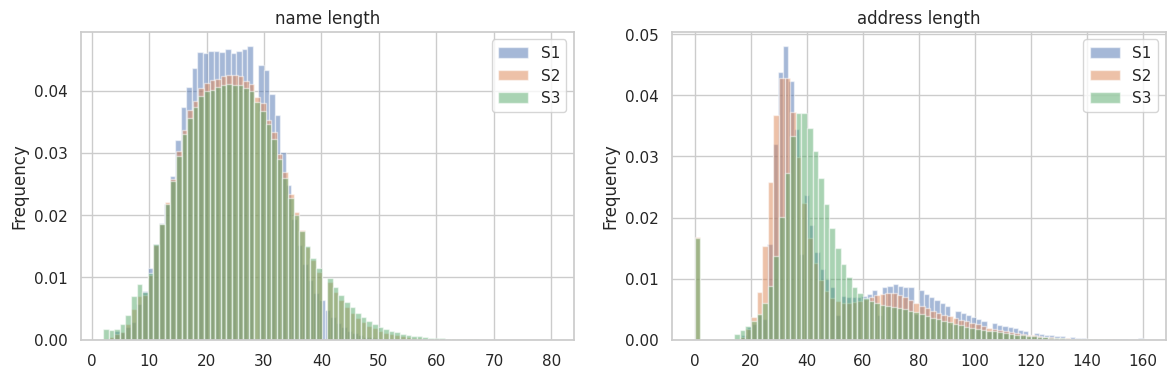

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for i in (1, 2, 3):
    tr[i].business_name.str.len().clip(upper=80).plot.hist(bins=80, alpha=.5, ax=ax[0], label=f'S{i}', density=True)
    tr[i].business_address.str.len().clip(upper=160).plot.hist(bins=80, alpha=.5, ax=ax[1], label=f'S{i}', density=True)
ax[0].set_title('name length'); ax[1].set_title('address length'); ax[0].legend(); ax[1].legend();

## 6. Address format

In [15]:
def addr_stats(df):
    a = df.business_address
    return pd.DataFrame({
        'n_parts': a.str.count(',') + (a != '').astype(int),
        'has_digit': a.str.contains(r'\d'),
        'has_pin6': a.str.contains(r'\b\d{6}\b'),
        'has_zip5': a.str.contains(r'\b\d{5}\b'),
        'has_near': a.str.contains(r'\b(?:near|opp|opposite|behind)\b', case=False),
        'upper': a.str.isupper(),
    })

rows = {}
for sp, d in [('train', tr), ('test', te)]:
    for i in (1, 2, 3):
        for c in d[i].country.unique():
            rows[(sp, f'S{i}', c)] = addr_stats(d[i][d[i].country == c].sample(100_000, random_state=0)).mean()
pd.DataFrame(rows).T.sort_index().style.format('{:.2f}')

In [16]:
# Last comma part = usually the state; see how states are written
for c in ['US', 'India']:
    last = pd.concat([tr[i][tr[i].country == c] for i in (1, 2, 3)]).business_address.str.split(',').str[-1].str.strip()
    print(c, last.value_counts().head(30).to_dict(), '\n')

US {'TX': 381621, 'NY': 293307, 'NC': 270800, 'Texas': 253243, 'OH': 244269, '': 222089, 'IL': 216286, 'New York': 194231, 'North Carolina': 179426, 'VA': 170987, 'TN': 170732, 'MA': 162236, 'AZ': 161973, 'Ohio': 161663, 'Illinois': 143592, 'IN': 141176, 'WA': 120692, 'MD': 115979, 'Virginia': 113199, 'Tennessee': 113021, 'Massachusetts': 107566, 'Arizona': 107208, 'CA': 106846, 'Indiana': 93809, 'AL': 93262, 'WI': 89890, 'MN': 89004, 'OR': 85617, 'KY': 84244, 'Washington': 81445} 



India {'Maharashtra': 460193, 'Delhi': 292092, 'MH': 268344, 'महाराष्ट्र': 183838, 'Uttar Pradesh': 176717, 'DL': 170480, 'Karnataka': 168618, 'Tamil Nadu': 152159, 'Gujarat': 137922, 'West Bengal': 137383, '': 122796, 'Telangana': 118618, 'दिल्ली': 115612, 'UP': 103247, 'KA': 98032, 'TN': 88283, 'Haryana': 86064, 'Andhra Pradesh': 84447, 'WB': 80634, 'GJ': 80490, 'Rajasthan': 77464, 'Kerala': 74742, 'उत्तर प्रदेश': 70670, 'ಕರ್ನಾಟಕ': 66935, 'TG': 62614, 'தமிழ்நாடு': 60272, 'Bihar': 55084, 'পশ্চিমবঙ্গ': 54618, 'ગુજરાત': 54467, 'Madhya Pradesh': 54162} 



In [17]:
# Matched pairs: address format variation side by side
pd.DataFrame({'s1_addr': L.business_address, 'other_addr': R.business_address, 'country': L.country}).sample(15, random_state=2)

,s1_addr,other_addr,country
286018,"47 Clifton Street, Babylon, NY","47 Clifton Street, Farmingdale CDP, New York",US
210531,"567 Lincoln Quarters Lane, Tega Cay, SC","FORT MIL CITY, 567 Lincoln Quarters Ln, South Carolina",US
200852,"1006 Stonybrook Drive, Ofallon, IL","1006 Stonybrook Dr, Ofallon, Illinois",US
209510,"2561 Harper Street, CA, Ontario","2561 HARPER ST, ONTARIO, CA",US
287994,"18925 Shore Pointe Court, Unit 2104, Rehoboth Beach, DE","1892 Shore Pointe Court, REHOBOTH BEACH, DE",US
103148,"Office No. 816, 8Th Floor, Vashi Infotech Park, Plot No. 16, Sect. 30A, Vashi- Navi Mumbai, Thane, Maharashtra","Office No. 816, 8Th Floor, Vashi Infotech Park, Plot No. 16, Sect. 30A, Vashi- Navi Mumbai, Thane, MH",India
215536,"615 Sixth Street, Fulton, TX","615 6th Street, Texas, Fultn",US
122517,"Flat No. A/01, Al-Ashraf Apt, Ghasswala C Omp, Thane, Maharashtra","FLAT NO. A/01, AL-ASHRAF APT, GHASSWALA C OMP, THANE, Maharashtra",India
225078,"1356 3rd Avenue, Huntington, WV","135 3TH AVENUE, HUNTINGTON, WV",US
133097,"Near Bhupat Jin, Nr Yogesh Appartment, Botad, Bhavnagar, Gujarat","Near Bhupat Jin, Nr Yogesh Appartment, Bhavnagar, Botad, GJ",India


## 7. Pair-level similarity: positives vs negatives

Cheap similarity measures on:
- **positives**: true pairs
- **random negatives**: a random same-country S2/S3 record
- **hard negatives**: an S2/S3 record belonging to a *different* S1 that has the *same normalized name*

In [18]:
def norm_name(s):
    return ' '.join(toks(s))

def jacc(a, b):
    a, b = set(a), set(b)
    return len(a & b) / max(1, len(a | b))

def grams(s, n=3):
    s = f' {s} '
    return {s[i:i + n] for i in range(len(s) - n + 1)}

def pair_feats(Ld, Rd):
    ln, rn = Ld.business_name.map(norm_name), Rd.business_name.map(norm_name)
    la, ra = Ld.business_address.map(norm_name), Rd.business_address.map(norm_name)
    return pd.DataFrame({
        'name_tok_jacc': [jacc(a.split(), b.split()) for a, b in zip(ln, rn)],
        'name_3g_jacc': [jacc(grams(a), grams(b)) for a, b in zip(ln, rn)],
        'addr_tok_jacc': [jacc(a.split(), b.split()) for a, b in zip(la, ra)],
        'addr_num_overlap': [bool(set(re.findall(r'\d+', a)) & set(re.findall(r'\d+', b)))
                             for a, b in zip(Ld.business_address, Rd.business_address)],
        'other_addr_empty': (Rd.business_address.str.strip() == '').values,
        'other_non_latin': (Rd.business_name.map(script_of) != 'LATIN').values,
    })

N = 50_000
Lp, Rp = L.iloc[:N], R.iloc[:N]
pos = pair_feats(Lp, Rp)

others = pd.concat([tr[2], tr[3]])
Ln = pd.concat([Lp[Lp.country == c] for c in ['US', 'India']]).reset_index(drop=True)
Rn = pd.concat([others[others.country == c].sample((Lp.country == c).sum(), random_state=0)
                for c in ['US', 'India']]).reset_index(drop=True)
neg = pair_feats(Ln, Rn)

In [19]:
# Hard negatives: S1 A paired with a true match of S1 B, where A and B share a normalized name
s1 = tr[1].copy()
s1['nn'] = s1.business_name.map(norm_name)
dup = s1[s1.nn.duplicated(keep=False)]
print('S1 rows whose normalized name is shared with another S1:', f'{len(dup) / len(s1):.2%}')
display(dup.nn.value_counts().head(10))

hard_L, hard_R = [], []
for nn, grp in dup.groupby('nn', sort=False):
    if len(hard_L) >= N:
        break
    ids = grp.entity_id.tolist()
    for a, b in zip(ids, ids[1:] + ids[:1]):
        if g_ids[b]:
            hard_L.append(a); hard_R.append(g_ids[b][0])
hard = pair_feats(rec.loc[hard_L].reset_index(), rec.loc[hard_R].reset_index())
print('hard negatives built:', len(hard))

S1 rows whose normalized name is shared with another S1: 39.28%


nn
primary care group         253
ear nose throat group      251
pediatric group            222
womens health group        220
physical therapy group     218
pediatric dental group     216
behavioral health group    215
chiropractic group         209
orthopedic group           208
eye group                  207
Name: count, dtype: int64

hard negatives built: 50025


kind,hard_neg,positive,random_neg
name_tok_jacc,0.485,0.641,0.032
name_3g_jacc,0.520,0.684,0.036
addr_tok_jacc,0.018,0.612,0.015
addr_num_overlap,0.027,0.798,0.027
other_addr_empty,0.030,0.044,0.033
other_non_latin,0.312,0.073,0.074


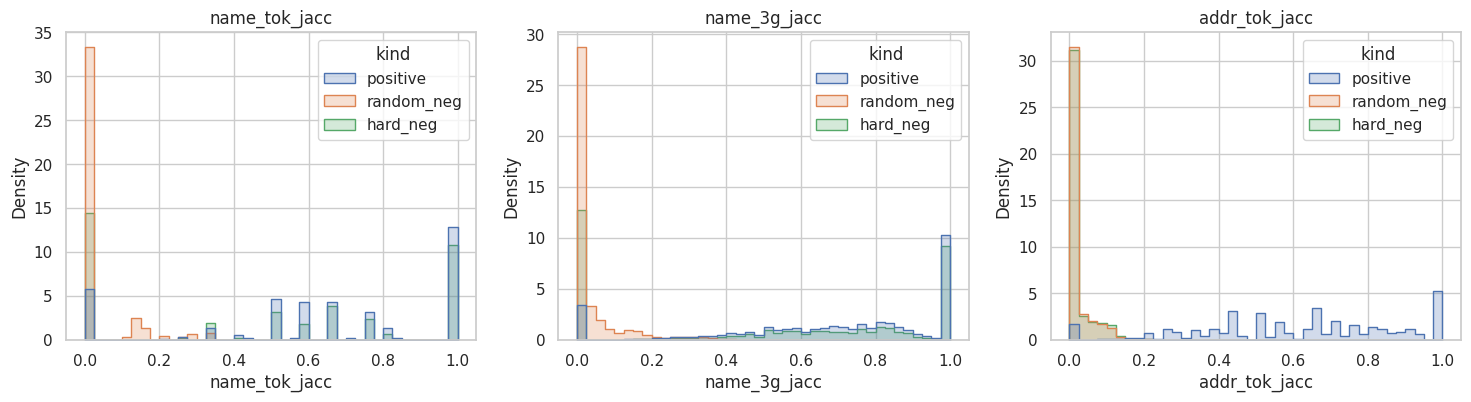

In [20]:
cmp = pd.concat({'positive': pos, 'random_neg': neg, 'hard_neg': hard}, names=['kind']).reset_index(level=0)
display(cmp.groupby('kind').mean().T.style.format('{:.3f}'))

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, col in zip(axes, ['name_tok_jacc', 'name_3g_jacc', 'addr_tok_jacc']):
    sns.histplot(cmp, x=col, hue='kind', bins=40, stat='density', common_norm=False, element='step', ax=ax)
    ax.set_title(col)

In [21]:
# Positives that name-only blocking would miss
z = pos.name_tok_jacc == 0
print('positives with zero name-token overlap:', f'{z.mean():.2%}')
print('  ...of which other side is non-Latin:', f'{pos[z].other_non_latin.mean():.2%}')
print('  ...and also no shared address number:', f'{(z & ~pos.addr_num_overlap).mean():.2%}')
pd.DataFrame({'s1_name': Lp.business_name[z], 'other_name': Rp.business_name[z],
              's1_addr': Lp.business_address[z], 'other_addr': Rp.business_address[z]}).sample(15, random_state=0)

positives with zero name-token overlap: 14.48%
  ...of which other side is non-Latin: 47.04%
  ...and also no shared address number: 2.30%


,s1_name,other_name,s1_addr,other_addr
244,A Cure 3 You LLC,Cure3you.Com,"17956 Hwy 412, Springdale, AR","17956 1/2 Hwy 412, Springdale, Arkansas"
5251,Synsoft,Snyfsoift,"168 Kanawha Avenue, Columbus, OH","168 Kanawha Ave, Columbus, Ohio"
10490,Board of Consumer Affairs,boardconsumeraffairs.com,"1106 Pershing Avenue, Garden City, KS","Garden CITY, 1106 Pershing Avenue, Kansas"
19809,Alpha Producer Private Limited,अल्फा प्रोड्यूसर प्राइवेट लिमिटेड,"C/Okr.Gaurav, Singh Niwas, Vishnuviharcolony, Shahpur, Sampatchak, Patna, Bihar","C/okr.gaurav, Singh Niwas, Vishnuviharcolony, Shahpur, Sampatchak, Patna, BR"
39622,Star Trading Private Limited,स्टार ट्रेडिंग प्राइवेट लिमिटेड,"L.G.10, Ratnamani Complex, Indore, Madhya Pradesh","BLOCK C-00471 L.G.10, RATNAMANI COMPLEX, INDORE, Madhya Pradesh"
40590,Innovate Services Private Limited,Innovateservices.Com,"Nashik, Maharashtra, Flat No 14 Hillside Appt, Nashik, Mahatma Ngr Nr Water Tank","Nashik, Door No 14 Hillside Appt, MH"
8971,Om Investment,ଓଁ ଇନଭେଷ୍ଟମେଣ୍ଟ୍,"Plot No. 2C/200, Sector 9, Cda Abhinav Bidanasi, Cuttack, Orissa","PLOT NO. G-2C/200, CUTTACK, Orissa"
33088,Regional Center,regionalcenter.com,"NC, Winterville, 2478 Red Forbes Road","#2478 RED FORBES RD, WINERVILLE CITY, NC"
32045,Collete's Publishing,colletespublishing.com,"29531 Perdido Beach Boulevard, Unit Unit 404, Orange Beach, AL","29531 Perdido Beach Blvd, Unit Unit 404, Baldwin County, Alabama"
24264,Fortune Ventures Private Limited,फॉर्च्यून वेंचर्स प्राइवेट लिमिटेड,"Delhi, South Delhi, 1, New Delhi, Birbal Road, 1St Floor Jangpura Extn.","Plot 188 1, New Delhi, South Delhi, DL"


## 8. Test set & the unseen country (France)

In [22]:
for i in (1, 2, 3):
    print(f'--- test S{i} France')
    display(te[i][te[i].country == 'France'].sample(6, random_state=0))

--- test S1 France


,entity_id,business_name,business_address,country
1225253,S1-258113226,Shidokan Ecole SARL,"17 Rue de Valmy, Lille, Hauts-de-France",France
1337759,S1-643804435,Pique Ecole EURL,"20 BD Jules Verne, Nantes, Pays de la Loire",France
1320154,S1-230207052,Chambre Medico SARL,"5 Avenue Gaston Bonnier, Nantes, Pays de la Loire",France
1537396,S1-759071723,Supérieure Sante EURL,"9 Rue Rubens, Lille, Hauts-de-France",France
1253696,S1-267637237,Vidourle Boulistes Élémentaire SAS,"Pessac, 59 Avenue des Echoppes, Nouvelle-Aquitaine",France
1171124,S1-811528684,EHPAD Saint Sophro,"12 RUE de lOrne, 44800, Saint-Herblain, Pays de la Loire",France


--- test S2 France


,entity_id,business_name,business_address,country
3711033,S2-124594349,Ciraecto,"33 BIS RUE PRUNIER, Bordeaux, Gironde",France
1731558,S2-726354849,Aikido Anciens,"51 R DE LA PLANCHE AU GUE, NANTES, Pays de la Loire",France
3146662,S2-733258288,Fédération du Musical,"3 R MIMEREL, ROUBAIX, Hauts-de-France",France
4353464,S2-836221765,CW Groupe,"28 R. PIERRE MAUROY, FLCAS, LILLE",France
4876915,S2-977094934,RI Amicale SARL,"13 RUE ALPHONSE MERCIER, LILLE, Nord",France
2322583,S2-382859363,JOURS ÇONCEPT SCI,"41 C RUE DU MARECHAL FRENCH, DUNKERQUE",France


--- test S3 France


,entity_id,business_name,business_address,country
4685555,S3-94181786,Amicale-Marseillaise du,"25 R Rue Albert Doyen, Dunkerque, Hauts-de-France",France
2303023,S3-624979045,Chantons Tgavsax SA,"N°23 R. D'arras, Lille, Nord",France
4794556,S3-648411774,Ets Alter,"120 R. D' Anvers, Tourcoing, Hauts-de-France",France
4937796,S3-652097034,Union dû Organisme,"196 Cours De L'argonne, Bordeaux",France
2961660,S3-84595509,Bonne-Solutions SAS,"Nº 257 Route De La Côte D'amour, Saint-nazaire",France
3024098,S3-328131909,Maison Team EI,"20 Av. Gorge V, Mérignac, Gironde",France


In [23]:
fr_addr = fr.business_address
display(fr_addr.str.split(',').str[-1].str.strip().value_counts().head(25))
print('France top address tokens:', Counter(t for a in fr_addr.sample(200_000, random_state=0) for t in toks(a)).most_common(40))

business_address
Hauts-de-France       250062
Nouvelle-Aquitaine    209990
Pays de la Loire      179271
Nord                  130449
Gironde               130391
Loire-Atlantique      110013
Bordeaux               46187
                       43084
Nantes                 40414
Lille                  36756
BORDEAUX               34618
NANTES                 30485
LILLE                  27832
Pas-de-Calais          24132
Tourcoing              19378
Dunkerque              18492
Roubaix                17632
Calais                 16971
TOURCOING              14620
Pessac                 13946
DUNKERQUE              13672
ROUBAIX                13115
CALAIS                 12628
PESSAC                 10193
Mérignac                8676
Name: count, dtype: int64

France top address tokens: [('de', 123757), ('rue', 86118), ('la', 56777), ('r', 42014), ('loire', 39243), ('france', 34788), ('hauts', 34357), ('bordeaux', 32975), ('nouvelle', 28510), ('aquitaine', 28477), ('nantes', 28227), ('du', 26270), ('lille', 26153), ('pays', 24448), ('des', 23306), ('gironde', 18031), ('nord', 17799), ('saint', 16685), ('calais', 15168), ('avenue', 14960), ('atlantique', 14835), ('tourcoing', 13826), ('dunkerque', 12952), ('roubaix', 12747), ('no', 11142), ('nazaire', 10371), ('pessac', 9670), ('buch', 8639), ('teste', 8636), ('merignac', 7534), ('cap', 7319), ('ferret', 7160), ('av', 6767), ('bis', 6231), ('allee', 6158), ('lege', 6113), ('pornic', 5823), ('n', 5595), ('herblain', 5276), ('jean', 5236)]


In [24]:
# S2+S3 records per S1, train vs test
for sp, d in [('train', tr), ('test', te)]:
    for c in sorted(set(d[1].country)):
        n1 = (d[1].country == c).sum(); n23 = sum((d[i].country == c).sum() for i in (2, 3))
        print(f'{sp:5s} {c:7s} S1={n1:>9,}  S2+S3={n23:>10,}  ratio={n23 / n1:.2f}')

train India   S1=  883,188  S2+S3= 4,133,346  ratio=4.68


train US      S1=1,323,633  S2+S3= 6,186,873  ratio=4.67


test  France  S1=  259,452  S2+S3= 1,434,993  ratio=5.53


test  India   S1=  809,986  S2+S3= 4,717,565  ratio=5.82


test  US      S1=  663,106  S2+S3= 3,817,031  ratio=5.76


## 9. Takeaways

- Each S2/S3 record links to **at most one** S1 → treat matching as an assignment: argmax S1 per record, or none.
- ~26% of S2/S3 records are **decoys** with no S1 match.
- Matches always share **country** → block within country (open set of labels; France appears only in test).
- Many S1 records share the same name → **address must disambiguate**; build hard negatives from same-name groups.
- ~15% of positives have zero name-token overlap (non-Latin scripts, trade names, domains) → need address-based and
  transliteration / embedding-based blocking in addition to name blocking.
- Address noise: case, `null` tokens, component reordering, state abbreviations vs full names vs native script,
  zero-padded numbers, typos in street/city names.